# Notebook 2 of 3 - Evaluation & Crater Extraction

Loads the trained U-Net model and does all crater extraction and analysis. This notebook does **not** need to be run by the supervisor.

**Notes on this notebook**

It has two parts with different settings, on purpose:
- **Part I** compares two extraction methods on the U-Net masks to see how they perform. Evaluated in pixels only (1-100, 1-50 and 5-50 px radius). Kept fast with 2000 test tiles.
- **Part II** compares the chosen U-Net method against the classical baseline. Uses the same pixel-radius bands as Part I as a quick carried-over check, then evaluates in kilometres (5-200 km diameter) for the final result, since physical size is what matters for the dating bias. Broadened to 4000 test tiles for this final evaluation.
- **Units:** pixel sizes are always radius, kilometre sizes always diameter.

**Contents of this notebook**

Part I: Choosing the extraction method
1. Setup and model
2. Extraction methods
3. Method comparison

Part II: Final evaluation: baseline vs. U-Net
1. Baseline and U-Net extraction
2. Detection accuracy in pixels
3. Example tiles
4. Crater dating bias

### Imports

In [1]:
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import torch
import torch.nn as nn

from skimage.feature import match_template, peak_local_max
from skimage.measure import label, regionprops
from scipy.optimize import least_squares
from scipy import ndimage
from sklearn.cluster import DBSCAN

# Part I: Choosing the Extraction Method

## 1. Setup and Model

### 1.1 Model definition and loading

In [2]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1 = ConvBlock(in_ch,   base)
        self.e2 = ConvBlock(base,    base*2)
        self.e3 = ConvBlock(base*2,  base*4)
        self.e4 = ConvBlock(base*4,  base*8)
        self.b  = ConvBlock(base*8,  base*16)
        self.u4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2); self.d4 = ConvBlock(base*16, base*8)
        self.u3 = nn.ConvTranspose2d(base*8,  base*4, 2, stride=2); self.d3 = ConvBlock(base*8,  base*4)
        self.u2 = nn.ConvTranspose2d(base*4,  base*2, 2, stride=2); self.d2 = ConvBlock(base*4,  base*2)
        self.u1 = nn.ConvTranspose2d(base*2,  base,   2, stride=2); self.d1 = ConvBlock(base*2,  base)
        self.out = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        c1 = self.e1(x)
        c2 = self.e2(self.pool(c1))
        c3 = self.e3(self.pool(c2))
        c4 = self.e4(self.pool(c3))
        b  = self.b(self.pool(c4))
        x = self.d4(torch.cat([self.u4(b), c4], dim=1))
        x = self.d3(torch.cat([self.u3(x), c3], dim=1))
        x = self.d2(torch.cat([self.u2(x), c2], dim=1))
        x = self.d1(torch.cat([self.u1(x), c1], dim=1))
        return torch.sigmoid(self.out(x))

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = UNet().to(device)
model.load_state_dict(torch.load('crater_unet_best.pt', map_location=device)) # weights from Notebook 1
model.eval() # inference mode (BatchNorm uses stored stats), no training here
print('model loaded on', device)

model loaded on cuda


### 1.2 Load test data

In [4]:
SRC_IMAGES  = 'Data/test_images.hdf5'
SRC_CRATERS = 'Data/test_craters.hdf5'
N = 4000

def load_subset(images_path, n):
    with h5py.File(images_path, 'r') as fh:
        X = fh['input_images'][:n].astype('float32') / 255.0 # DEM 0-255 -> 0-1 (same as training)
        Y = fh['target_masks'][:n].astype('float32')
        # per-tile geo metadata is stored in groups (key img_{i:05d}), read each entry
        ll = fh['longlat_bounds']
        di = fh['pix_distortion_coefficient']
        longlat_bounds = [ll[f'img_{i:05d}'][()] for i in range(n)]   # each: [lon_min, lon_max, lat_min, lat_max]
        distortion     = [di[f'img_{i:05d}'][()][0] for i in range(n)] # each: single distortion coefficient
    return X[..., np.newaxis], Y[..., np.newaxis], longlat_bounds, distortion

def to_tensor(X):
    return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous() # NHWC -> NCHW

X, Y, longlat_bounds, distortion = load_subset(SRC_IMAGES, N)
print('loaded', X.shape, 'from', SRC_IMAGES)

loaded (4000, 256, 256, 1) from Data/test_images.hdf5


In [5]:
stored = pd.HDFStore(SRC_CRATERS, 'r')
cat = stored['/img_00000']
print(cat.head())
stored.close()

   Diameter (km)        Lat       Long           x           y  Diameter (pix)
0      18.297067  34.843656  78.402402   96.888963  252.787305       13.720095
1       5.534373  34.895820  75.537882   43.525105  249.735191        4.149961
2      11.937987  34.900356  74.868814   31.087116  248.947213        8.951726
3       7.566511  34.929841  78.266321   94.383777  250.783833        5.673765
4       6.034980  34.997882  84.224432  205.410156  247.765640        4.525343


In [6]:
with h5py.File(SRC_IMAGES, 'r') as fh:
    print("longlat_bounds type:", type(fh['longlat_bounds']))
    print("distortion type:    ", type(fh['pix_distortion_coefficient']))
    g = fh['pix_distortion_coefficient']
    if hasattr(g, 'keys'):
        keys = list(g.keys())[:3]
        print("distortion subkeys:", keys)
        print("example value:", g[keys[0]][()])
    ll = fh['longlat_bounds']
    if hasattr(ll, 'keys'):
        keys = list(ll.keys())[:3]
        print("longlat subkeys:", keys)
        print("example value:", ll[keys[0]][()])

longlat_bounds type: <class 'h5py._hl.group.Group'>
distortion type:     <class 'h5py._hl.group.Group'>
distortion subkeys: ['img_00000', 'img_00001', 'img_00002']
example value: [0.98916814]
longlat subkeys: ['img_00000', 'img_00001', 'img_00002']
example value: [74.5        85.63671875 34.71484375 45.8515625 ]


### 1.3 Apply the U-Net: predicted masks

In [7]:
@torch.no_grad() # switching to no gradient calculation, only applying the built model
def predict(X, batch=16):
    model.eval()
    out = []
    for i in range(0, len(X), batch):
        xb = to_tensor(X[i:i+batch]).to(device) # 16 tiles per Batch again
        out.append(model(xb).cpu().numpy()[:, 0]) # (b, 256, 256) probability masks
    return np.concatenate(out) # layer of all probability masks

preds = predict(X)
print('predicted masks:', preds.shape, '| value range', round(float(preds.min()),3), '-', round(float(preds.max()),3))

predicted masks: (4000, 256, 256) | value range 0.0 - 1.0


In [8]:
np.save('preds_test.npy', preds)
print('saved preds_test.npy', preds.shape)

print(np.unique(preds[0]).shape) # how many values
print(np.unique(preds[0])[:8])

saved preds_test.npy (4000, 256, 256)
(55151,)
[0.000000e+00 2.939812e-39 2.950867e-39 2.956005e-39 2.960970e-39
 2.970111e-39 2.975782e-39 2.978234e-39]


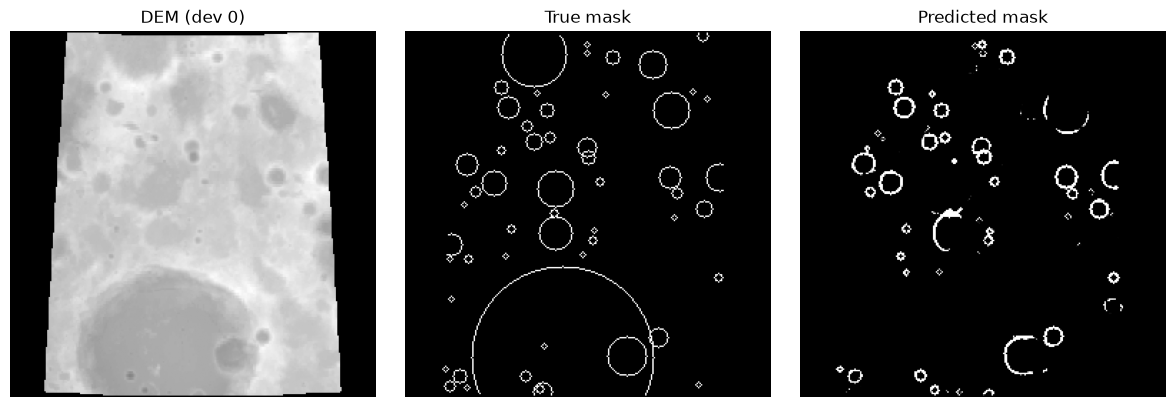

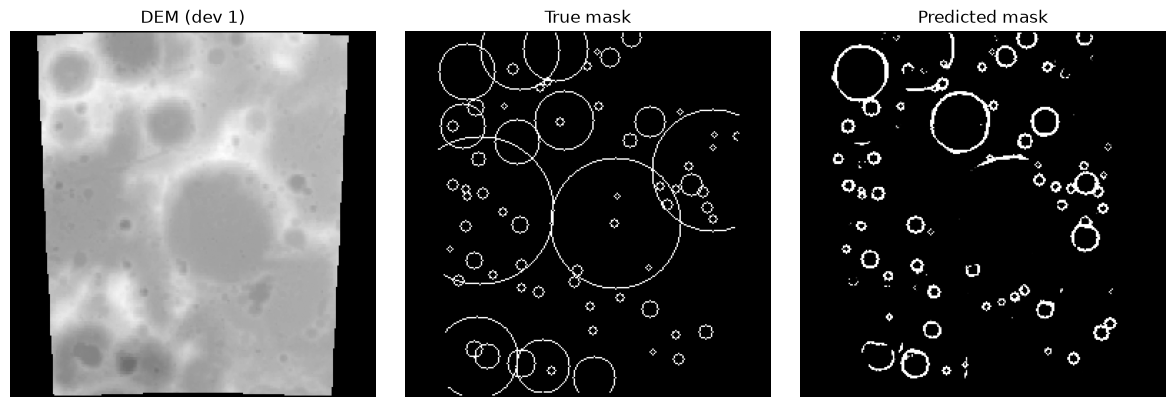

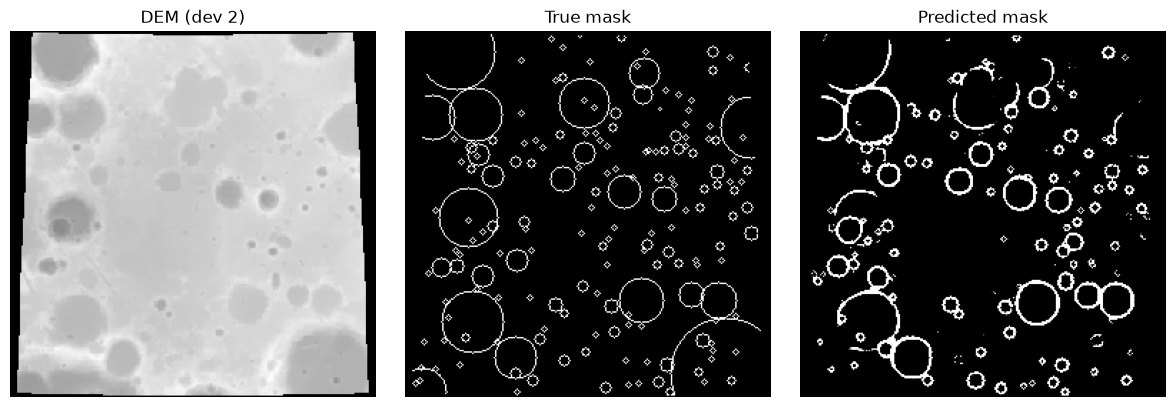

In [9]:
# quick look: DEM, true mask, predicted mask
for j in [0, 1, 2]:
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(X[j, ..., 0], cmap='gray'); ax[0].set_title(f'DEM (dev {j})')
    ax[1].imshow(Y[j, ..., 0], cmap='gray'); ax[1].set_title('True mask')
    ax[2].imshow(preds[j],     cmap='gray'); ax[2].set_title('Predicted mask')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

### 1.4 Pixel-to-kilometre conversion (per tile)

Each tile is a different crop of the Moon, so km-per-pixel varies per tile. Pixel radii are converted to kilometre diameters using the per-tile longitude/latitude bounds.

In [11]:
def km_per_pix(j):
    lon_min, lon_max, lat_min, lat_max = longlat_bounds[j]
    lat_centre = (lat_min + lat_max) / 2
    lon_range  = lon_max - lon_min
    km_per_deg = 30.32 * np.cos(np.radians(lat_centre))
    base_km_per_pix = (lon_range / 256) * km_per_deg
    return base_km_per_pix * float(distortion[j]) # distortion correction now applied here, once

def diam_px_to_km(r_pix, j):
    return 2 * r_pix * km_per_pix(j) # km_per_pix already includes the distortion correction


## 2. Extraction methods

### 2.1 Method A: template matching

Template matching on the binarised U-Net mask, then duplicate removal by size + position.

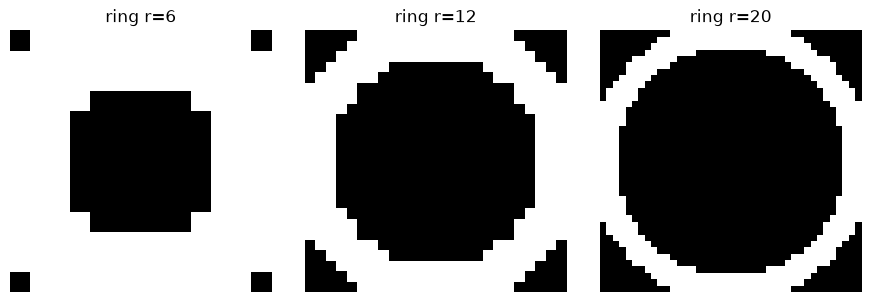

In [12]:
def make_ring(r, thickness=2):
    size = 2*r + 1 # template big enough for the whole ring
    yy, xx = np.ogrid[:size, :size] # coordinates of every pixel
    dist = np.sqrt((xx - r)**2 + (yy - r)**2) # distance of each pixel to the center (r, r)
    return (np.abs(dist - r) <= thickness).astype(np.float32) # white only where dist ~ r -> ring

# examples
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, r in zip(ax, [6, 12, 20]):
    a.imshow(make_ring(r), cmap='gray'); a.set_title(f'ring r={r}'); a.axis('off')
plt.tight_layout(); plt.show()

In [13]:
# binarise the mask first, then template-match, then remove duplicates by size+position
def detect_craters_deepmoon(mask, B=0.3, radii=range(1, 100), Pm=0.38, D_xy=1.8, D_r=1.0):
    # parameters: Pm = peak (correlation) threshold; D_xy = duplicate position rule; D_r = duplicate size rule
    binary = (mask > B).astype(np.float32) # turn the soft 0-1 mask into hard rings (above threshold B)
    raw = []
    for r in radii: # try every ring radius, since crater sizes vary
        if 2*r + 1 >= min(binary.shape): # skip templates bigger than the tile
            continue
        corr = match_template(binary, make_ring(r), pad_input=True) # match of the ring at each position
        for y, x in peak_local_max(corr, threshold_abs=Pm, min_distance=4): # keep strong, separated peaks
            raw.append((x, y, r, corr[y, x])) # candidate (x, y, r, score)
    # remove duplicates: many ring sizes fire on the same crater, keep only the best
    kept = []
    for x, y, r, s in sorted(raw, key=lambda d: -d[3]): # strongest match first
        dup = False
        for kx, ky, kr, _ in kept: # compare against everything already kept
            same_place = ((x-kx)**2 + (y-ky)**2) / min(r, kr)**2 < D_xy # centres close relative to size
            same_size  = abs(r - kr) / min(r, kr) < D_r # radii similar relative to size
            if same_place and same_size: # only a duplicate if both hold
                dup = True
                break
        if not dup:
            kept.append((x, y, r, s))
    return kept

In [14]:
# wrap as extractor: tile index -> list of (x, y, r, score)
def extract_template(j):
    return detect_craters_deepmoon(preds[j], Pm=0.38)


### 2.2 Method B: circle-and-arc fitting (multi-stage)

Stage 1 fits circles to connected components, stage 2 erases found rims, stage 3 recovers partial arcs in the residual, then IoU-based NMS.

In [15]:
R_MIN_PX = 1
R_MAX_PX = 100

def get_radius_range(tile_idx):
    return R_MIN_PX, R_MAX_PX

# intersection over union
def circle_iou(d1, d2):
    x1, y1, r1 = d1[0], d1[1], d1[2]
    x2, y2, r2 = d2[0], d2[1], d2[2]
    dist = np.sqrt((x1-x2)**2 + (y1-y2)**2)
    if dist >= r1 + r2: return 0.0 # separate circles
    if dist <= abs(r1 - r2): # one circle is inside the other circle
        smaller = min(r1, r2)**2
        larger  = max(r1, r2)**2
        return (np.pi * smaller) / (np.pi * larger + 1e-8)
    r1_sq  = r1**2 # partial overlapping circles
    r2_sq  = r2**2
    d_sq   = dist**2
    cos_a1 = np.clip((d_sq+r1_sq-r2_sq)/(2*dist*r1+1e-8), -1, 1)
    cos_a2 = np.clip((d_sq+r2_sq-r1_sq)/(2*dist*r2+1e-8), -1, 1)
    a1     = np.arccos(cos_a1)
    a2     = np.arccos(cos_a2)
    intersection = (r1_sq*(a1-np.sin(2*a1)/2) + r2_sq*(a2-np.sin(2*a2)/2))
    union = np.pi*(r1_sq+r2_sq) - intersection
    return intersection / (union + 1e-8)

# circle fitting function
def fit_circle_to_points(x_points, y_points):
    if len(x_points) < 5: return None
    # first initial guess of center point and radius
    cx0 = np.mean(x_points)
    cy0 = np.mean(y_points)
    r0  = np.mean(np.sqrt((x_points-cx0)**2 +
                           (y_points-cy0)**2))
    if r0 < 1: return None
    # optimizer, to find (cx, cy, r) that makes all these residuals as close to zero as possible
    def residuals(params):
        cx, cy, r = params
        dist = np.sqrt((x_points-cx)**2 + (y_points-cy)**2)
        return dist - r
    try:
        # runs the actual optimization, starting from the rough guess
        result    = least_squares(residuals, x0=[cx0, cy0, r0],method='lm', max_nfev=500) # 'lm': Levenberg-Marquardt algorithm, a standard robust method for nonlinear least-squares curve-fitting problem
        cx, cy, r = result.x # extracts the optimizer's final best-fit values
        residual  = np.mean(np.abs(result.fun))
        return cx, cy, abs(r), residual
    except Exception: return None # the optimizer fails for any reason, return None

# sanity check specific to fitting circles from partial arcs
def fit_circle_from_arc(x_points, y_points):
    if len(x_points) < 5: return None
    if max(x_points.max()-x_points.min(),y_points.max()-y_points.min()) < 5: return None # a genuine circular arc needs to actually curve across some meaningful physical extent for a circle fit to be geometrically meaningful
    return fit_circle_to_points(x_points, y_points)

# weighted circle fitting function
def fit_circle_to_points_weighted(x_points, y_points,weights=None):
    if len(x_points) < 5:return None
    if weights is None:weights = np.ones(len(x_points))
    weights = weights / (weights.sum() + 1e-8)
    cx0 = np.sum(weights * x_points)
    cy0 = np.sum(weights * y_points)
    r0  = np.mean(np.sqrt((x_points-cx0)**2 +(y_points-cy0)**2))
    if r0 < 1:return None
    def residuals(params):
        cx, cy, r = params
        dist = np.sqrt((x_points-cx)**2 + (y_points-cy)**2)
        return (dist - r) * weights * len(weights)
    try:
        result    = least_squares(residuals, x0=[cx0, cy0, r0],method='lm', max_nfev=500)
        cx, cy, r = result.x
        residual  = np.mean(np.abs(result.fun / (weights*len(weights)+1e-8)))
        return cx, cy, abs(r), residual
    except Exception:
        return None

# component splitting
# to split merged pixels from two or three separate nearby craters back apart into separate physical clusters using DBSCAN clustering
def split_component(x_points, y_points, min_cluster_size=5):
    if len(x_points) < min_cluster_size * 2: return [(x_points, y_points)]
    coords = np.column_stack([x_points, y_points])
    # DBSCAN essentially groups together points that form dense, connected neighborhoods, and separates points that don't
    db     = DBSCAN(eps=8, min_samples=min_cluster_size).fit(coords) # runs DBSCAN, a density-based clustering algorithm # eps=8 means: two points are considered "neighbors" if they're within 8 pixels of each other # a cluster needs at least 5 points close together to count as a real cluster
    labels = db.labels_ # an array assigning each input point a cluster ID (0, 1, 2, ...) or -1 if DBSCAN decided that point is noise
    groups = []
    for lab in set(labels):
        if lab == -1:continue
        mask = labels == lab
        if mask.sum() >= min_cluster_size:groups.append((x_points[mask], y_points[mask]))
    return groups if groups else [(x_points, y_points)]

# when a single-circle fit fails (eg. due to high residuals), split in half (either left/right or top/bottom) and fit two separate circles, one per half
def fit_two_circles(x_points, y_points):
    if len(x_points) < 15:return None
    x_mid  = np.median(x_points)
    y_mid  = np.median(y_points)
    left   = x_points <= x_mid
    right  = x_points > x_mid
    top    = y_points <= y_mid
    bot    = y_points > y_mid
    splits = []
    if left.sum() >= 5 and right.sum() >= 5: splits.append((left, right))
    if top.sum() >= 5 and bot.sum() >= 5: splits.append((top, bot))
    if not splits: return None
    best_result         = None
    best_total_residual = float('inf')
    for m1, m2 in splits:
        r1 = fit_circle_from_arc(x_points[m1], y_points[m1])
        r2 = fit_circle_from_arc(x_points[m2], y_points[m2])
        if r1 is None or r2 is None: continue
        total = (r1[3] + r2[3]) / 2
        if total < best_total_residual:
            best_total_residual = total
            best_result         = (r1, r2)
    return best_result


# STEP 1: circle fitting
# takes the binarized U-Net mask and turns connected blobs of rim pixels into actual crater detections (circles), using everything (fit_circle_to_points, split_component, fit_two_circles)
# max_residual: how loose a circle fit can be and still count
# min_coverage: how much of the ring's circumference needs to be actually present
# max_radius_fraction: the largest allowed radius as a fraction of the tile size
def detect_craters_from_mask(prob_mask, tile_idx, prob_threshold = 0.3, min_pixels = 10,max_residual = 2.5, min_coverage = 0.25, max_radius_fraction = 0.35, split_large = True, split_threshold = 200, try_two_circles = True):
    r_min, r_max = get_radius_range(tile_idx)
    r_abs_max       = int(256 * max_radius_fraction)
    binary  = (prob_mask > prob_threshold).astype(np.uint8)
    labeled = label(binary, connectivity=2)
    regions = regionprops(labeled)

    detections = []

    for region in regions:
        if region.area < min_pixels: continue
        coords   = region.coords
        y_pts    = coords[:, 0].astype(float)
        x_pts    = coords[:, 1].astype(float)
        if split_large and region.area > split_threshold: # only split > 200 pixels
            groups  = split_component(x_pts, y_pts)
        else:
            groups = [(x_pts, y_pts)]

        # circle fitting
        for x_grp, y_grp in groups:
            if len(x_grp) < min_pixels: continue
            result        = fit_circle_to_points(x_grp, y_grp)
            single_worked = False

            if result is not None:
                cx, cy, r, res = result
                margin   = r * 0.3
                expected = 2 * np.pi * r # number of pixels a complete ring of this radius should have (circumference 2πr)
                coverage = min(1.0, len(x_grp) / expected)

                if (r_min <= r <= min(r_max, r_abs_max) and
                        res <= max_residual and
                        margin <= cx < 256-margin and
                        margin <= cy < 256-margin and
                        coverage >= min_coverage):

                    detections.append({
                        'x': float(cx), 'y': float(cy),
                        'r': float(r),  'residual': float(res),
                        'coverage': float(coverage),
                        'n_pixels': int(len(x_grp)),
                        'source':   'circle'})
                    single_worked  = True
            #  if the single-circle fit either failed outright or failed the acceptance gate above (bad residual, wrong size, off-edge, or too little coverage, try two circles fit
            if (not single_worked and try_two_circles and len(x_grp) >= r_min * 4):
                two = fit_two_circles(x_grp, y_grp)
                if two is not None:
                    for cx, cy, r, res in two:
                        if not (r_min <= r <= min(r_max, r_abs_max)): continue
                        if res > max_residual * 1.5: continue
                        if not (0 <= cx < 256 and 0 <= cy < 256): continue
                        expected = 2 * np.pi * r
                        coverage = min(1.0, len(x_grp)/2 / expected)
                        if coverage < min_coverage * 0.5: continue
                        detections.append({
                            'x': float(cx), 'y': float(cy),
                            'r': float(r),  'residual': float(res),
                            'coverage': float(coverage),
                            'n_pixels': int(len(x_grp)//2),
                            'source':   'circle_pair'})
    return detections

# STEP 2: subtract detected rims
def subtract_detected_rims(prob_mask, detections,tile_idx, rim_thickness=4):
    residual       = prob_mask.copy()
    H, W           = prob_mask.shape
    y_grid, x_grid = np.ogrid[:H, :W]
    for d in detections:
        cx, cy, r    = d['x'], d['y'], d['r']
        dist_centre  = np.sqrt((x_grid-cx)**2 + (y_grid-cy)**2)
        dist_rim     = np.abs(dist_centre - r)
        residual[dist_rim <= rim_thickness] = 0.0
    return residual

# STEP 3: arc detection
def detect_arcs_improved(residual_mask, tile_idx,prob_threshold = 0.2, min_pixels = 8,max_residual = 6.0, min_span = 6, min_coverage = 0.10, max_radius_fraction = 0.45, split_large = True, split_threshold = 150):
    r_min, r_max = get_radius_range(tile_idx)
    r_abs_max       = int(256 * max_radius_fraction)

    binary  = (residual_mask > prob_threshold).astype(np.uint8)
    labeled = label(binary, connectivity=2)
    regions = regionprops(labeled)

    detections = []
    for region in regions:
        if region.area < min_pixels: continue
        coords  = region.coords
        y_pts   = coords[:, 0].astype(float)
        x_pts   = coords[:, 1].astype(float)

        if max(x_pts.max()-x_pts.min(), y_pts.max()-y_pts.min()) < min_span: continue

        if split_large and region.area > split_threshold: groups = split_component(x_pts, y_pts)
        else: groups = [(x_pts, y_pts)]

        for x_grp, y_grp in groups:
            if len(x_grp) < min_pixels: continue
            w_grp = np.array([residual_mask[int(y), int(x)] for x, y in zip(x_grp, y_grp)]) # weight: actual probability value at each of this region's pixels
            result = fit_circle_to_points_weighted(x_grp, y_grp, w_grp)
            if result is None: result = fit_circle_from_arc(x_grp, y_grp)
            if result is None: continue

            cx, cy, r, res = result

            if r < r_min or r > r_abs_max: continue
            if res > max_residual: continue
            if not (0 <= cx < 256 and 0 <= cy < 256):continue

            expected = 2 * np.pi * r
            coverage = min(1.0, len(x_grp) / expected)

            if coverage < min_coverage: continue

            detections.append({
                'x': float(cx), 'y': float(cy),
                'r': float(r),  'residual': float(res),
                'coverage': float(coverage),
                'n_pixels': int(len(x_grp)),
                'source':   'arc'})
    return detections

# full pipeline
def detect_all_craters(prob_mask, tile_idx):
    # step 1
    det_circles = detect_craters_from_mask(prob_mask, tile_idx = tile_idx, prob_threshold = 0.5, min_pixels = 10, max_residual = 2.5, min_coverage = 0.25, max_radius_fraction = 0.35, split_large = True, split_threshold = 200, try_two_circles = True)

    # step 2
    residual_mask = subtract_detected_rims(
        prob_mask, det_circles, tile_idx, rim_thickness=4)

    # step 3
    det_arcs = detect_arcs_improved(residual_mask, tile_idx = tile_idx, prob_threshold = 0.4, min_pixels = 5, max_residual = 6.0, min_span = 6, min_coverage = 0.10, max_radius_fraction = 0.45, split_large = True,split_threshold = 150)

    # combine + NMS
    all_raw = det_circles + det_arcs
    unified = [(d['x'], d['y'], d['r'], max(0.0, 1.0 - d['residual']*0.1),  d['source'], d['coverage'],                        d['residual'])  for d in all_raw]
    unified = sorted(unified, key=lambda d: d[3], reverse=True)

    # removing duplicates
    kept = []
    while unified:
        best = unified.pop(0)
        kept.append(best)
        unified = [d for d in unified if circle_iou(best, d) < 0.3]

    final = [{'x': x, 'y': y, 'r': r, 'nms_score': s, 'source': src, 'coverage': true_cov, 'residual': true_res} for x, y, r, s, src, true_cov, true_res in kept]

    return final, residual_mask

In [16]:
# wrap the pipeline as an extractor with the same interface: tile index -> list of (x, y, r, score)
def extract_circlearc(j):
    dets, _ = detect_all_craters(preds[j], tile_idx=j)   # returns list of dicts
    # convert to (x, y, r, score); use coverage as score for duplicate-ordering
    return [(d['x'], d['y'], d['r'], d.get('coverage', 1.0)) for d in dets]


### 2.3 Combination of both methods

In [17]:
# combination: union of both methods, template takes priority where they overlap
def extract_union(j, D_xy=1.8, D_r=1.0):
    tm = [(x,y,r,s) for x,y,r,s in extract_template(j)]
    ca = [(x,y,r,s) for x,y,r,s in extract_circlearc(j)]
    kept = []
    for x, y, r, s in tm + ca:
        dup = False
        for kx, ky, kr, _ in kept: # compare against everything already kept
            # same crater if centres close and radii similar (like above)
            if ((x-kx)**2+(y-ky)**2)/min(r,kr)**2 < D_xy and abs(r-kr)/min(r,kr) < D_r:
                dup = True; break # already have this crater: skip it
        if not dup:
            kept.append((x, y, r, s)) # new crater: keep it
    return kept

## 3. Method comparison

### 3.1 Accuracy in pixels (1-100, 5-50 and 1-50 px)

In [18]:
N_EVAL = 2000

In [19]:
# compare detections against the catalogue
def match_px_band(dets, cat, r_min, r_max, D_xy=1.8, D_r=1.0):
    # keep only catalogue craters whose radius is inside the band (r_min to r_max)
    truth = [(c['x'], c['y'], c['Diameter (pix)']/2)
             for _, c in cat.iterrows() if r_min <= c['Diameter (pix)']/2 <= r_max]
    # keep only detected craters whose radius is inside the band
    dets  = [d for d in dets if r_min <= d[2] <= r_max]
    matched = set() # which catalogue craters were found
    tp = 0 # true positives
    for x, y, r, *_ in sorted(dets, key=lambda d: -d[3]): # go through detections, strongest first
        for k, (tx, ty, tr) in enumerate(truth): # check against every catalogue crater
            if k in matched: continue # skip craters already matched (one match each)
            # match if centres close and radii similar
            if ((x-tx)**2+(y-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                tp += 1; matched.add(k); break  # hit: count it, mark the crater used, next detection
    return tp, len(dets)-tp, len(truth)-tp   # tp, fp (extra detections), fn (missed craters)

# run match_px_band over many tiles and sum up tp/fp/fn -> precision, recall, F1
def evaluate_px_band(n_tiles, extractor, r_min, r_max):
    TP = FP = FN = 0
    stored = pd.HDFStore(SRC_CRATERS, 'r')
    for j in range(n_tiles):
        cat = stored[f"/img_{j:05d}"]
        tp, fp, fn = match_px_band(extractor(j), cat, r_min, r_max)  # count for this tile
        TP += tp; FP += fp; FN += fn  # accumulate over all tiles
    stored.close()
    p = TP/(TP+FP+1e-9) # of what we detected, how much was real
    r = TP/(TP+FN+1e-9) # of all real craters, how many we found
    return p, r, 2*p*r/(p+r+1e-9)   # precision, recall, F1

for r_min, r_max in [(1,100), (1, 50), (5, 50)]:
    pt, rt, ft = evaluate_px_band(N_EVAL, extract_template,  r_min, r_max)
    pc, rc, fc = evaluate_px_band(N_EVAL, extract_circlearc, r_min, r_max)
    pu, ru, fu = evaluate_px_band(N_EVAL, extract_union,     r_min, r_max)
    print(f"\n=== pixel radius {r_min}-{r_max} px ===")
    print(f"{'method':<22} {'precision':>10} {'recall':>10} {'F1':>10}")
    print(f"{'A: template matching':<22} {pt:>10.3f} {rt:>10.3f} {ft:>10.3f}")
    print(f"{'B: circle+arc':<22} {pc:>10.3f} {rc:>10.3f} {fc:>10.3f}")
    print(f"{'C: union (A+B)':<22} {pu:>10.3f} {ru:>10.3f} {fu:>10.3f}")



=== pixel radius 1-100 px ===
method                  precision     recall         F1
A: template matching        0.781      0.212      0.333
B: circle+arc               0.822      0.421      0.557
C: union (A+B)              0.773      0.444      0.564

=== pixel radius 1-50 px ===
method                  precision     recall         F1
A: template matching        0.781      0.213      0.335
B: circle+arc               0.823      0.423      0.559
C: union (A+B)              0.774      0.447      0.566

=== pixel radius 5-50 px ===
method                  precision     recall         F1
A: template matching        0.666      0.682      0.674
B: circle+arc               0.796      0.653      0.717
C: union (A+B)              0.638      0.745      0.687


### 3.2 Recall & precision per radius

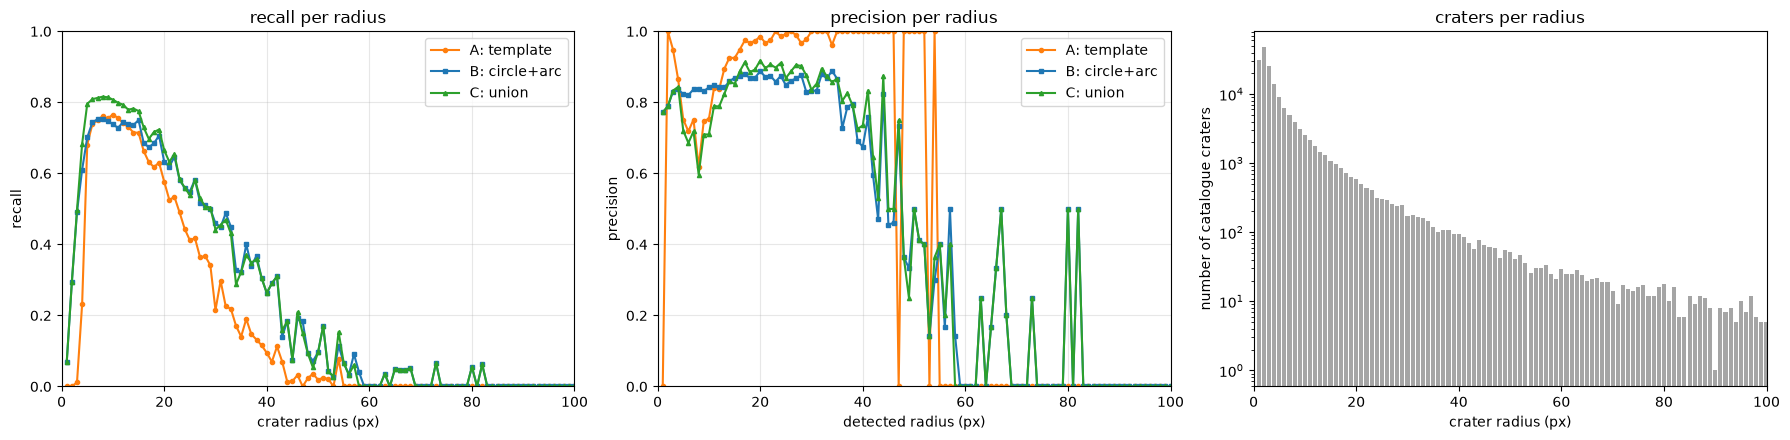

In [20]:
# for plotting recall & precision per radius
def curves_per_radius(extractor, n_tiles, r_min=1, r_max=100, D_xy=1.8, D_r=1.0):
    # count per radius bin: FN/n_truth binned by the true crater radius (for recall),
    # FP binned by the detected radius (for precision)
    tp_r = {}; fp_r = {}; fn_r = {}; nt_r = {}
    stored = pd.HDFStore(SRC_CRATERS, 'r')
    for j in range(n_tiles):
        cat = stored[f"/img_{j:05d}"]
        truth = [(c['x'], c['y'], c['Diameter (pix)']/2)
                 for _, c in cat.iterrows() if r_min <= c['Diameter (pix)']/2 <= r_max]
        dets = [d for d in extractor(j) if r_min <= d[2] <= r_max]
        # match detections to truth; remember which truth (matched_t) and which detections (matched_d) matched
        matched_t, matched_d = set(), set()
        for di, (x, y, r, *_ ) in enumerate(sorted(dets, key=lambda d: -d[3])):
            for k, (tx, ty, tr) in enumerate(truth):
                if k in matched_t: continue
                if ((x-tx)**2+(y-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                    matched_t.add(k); matched_d.add(di); break
        sd = sorted(dets, key=lambda d: -d[3])
        # each true crater -> its radius bin: counts toward n_truth, and TP if matched else FN
        for k, (tx, ty, tr) in enumerate(truth):
            rb = int(round(tr))
            nt_r[rb] = nt_r.get(rb, 0) + 1
            if k in matched_t: tp_r[rb] = tp_r.get(rb, 0) + 1
            else:              fn_r[rb] = fn_r.get(rb, 0) + 1
        # each unmatched detection -> its radius bin: counts as a false positive
        for di, d in enumerate(sd):
            rb = int(round(d[2]))
            if di not in matched_d: fp_r[rb] = fp_r.get(rb, 0) + 1
    stored.close()
    radii = sorted(nt_r)
    recall    = [tp_r.get(r,0)/(tp_r.get(r,0)+fn_r.get(r,0)+1e-9) for r in radii]
    precision = [tp_r.get(r,0)/(tp_r.get(r,0)+fp_r.get(r,0)+1e-9) for r in radii]
    counts    = [nt_r[r] for r in radii]
    return np.array(radii), np.array(recall), np.array(precision), np.array(counts)

rt_x, rt_rec, rt_prec, rt_n = curves_per_radius(extract_template,  N_EVAL)
rc_x, rc_rec, rc_prec, rc_n = curves_per_radius(extract_circlearc, N_EVAL)
ru_x, ru_rec, ru_prec, ru_n = curves_per_radius(extract_union,     N_EVAL)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
# recall
ax[0].plot(rt_x, rt_rec, 'o-', label='A: template',   color='tab:orange', ms=3)
ax[0].plot(rc_x, rc_rec, 's-', label='B: circle+arc', color='tab:blue',   ms=3)
ax[0].plot(ru_x, ru_rec, '^-', label='C: union',      color='tab:green',  ms=3)
ax[0].set_xlabel('crater radius (px)'); ax[0].set_ylabel('recall'); ax[0].set_title('recall per radius')
ax[0].set_ylim(0, 1); ax[0].set_xlim(0, 100); ax[0].legend(); ax[0].grid(alpha=0.3)
# precision
ax[1].plot(rt_x, rt_prec, 'o-', label='A: template',   color='tab:orange', ms=3)
ax[1].plot(rc_x, rc_prec, 's-', label='B: circle+arc', color='tab:blue',   ms=3)
ax[1].plot(ru_x, ru_prec, '^-', label='C: union',      color='tab:green',  ms=3)
ax[1].set_xlabel('detected radius (px)'); ax[1].set_ylabel('precision'); ax[1].set_title('precision per radius')
ax[1].set_ylim(0, 1); ax[1].set_xlim(0, 100); ax[1].legend(); ax[1].grid(alpha=0.3)
# crater counts
ax[2].bar(rt_x, rt_n, width=0.8, alpha=0.7, color='tab:gray')
ax[2].set_xlabel('crater radius (px)'); ax[2].set_ylabel('number of catalogue craters')
ax[2].set_title('craters per radius'); ax[2].set_xlim(0, 100); ax[2].set_yscale('log')
plt.tight_layout(); plt.show()

### 3.3 Visual check: both methods on the same tiles

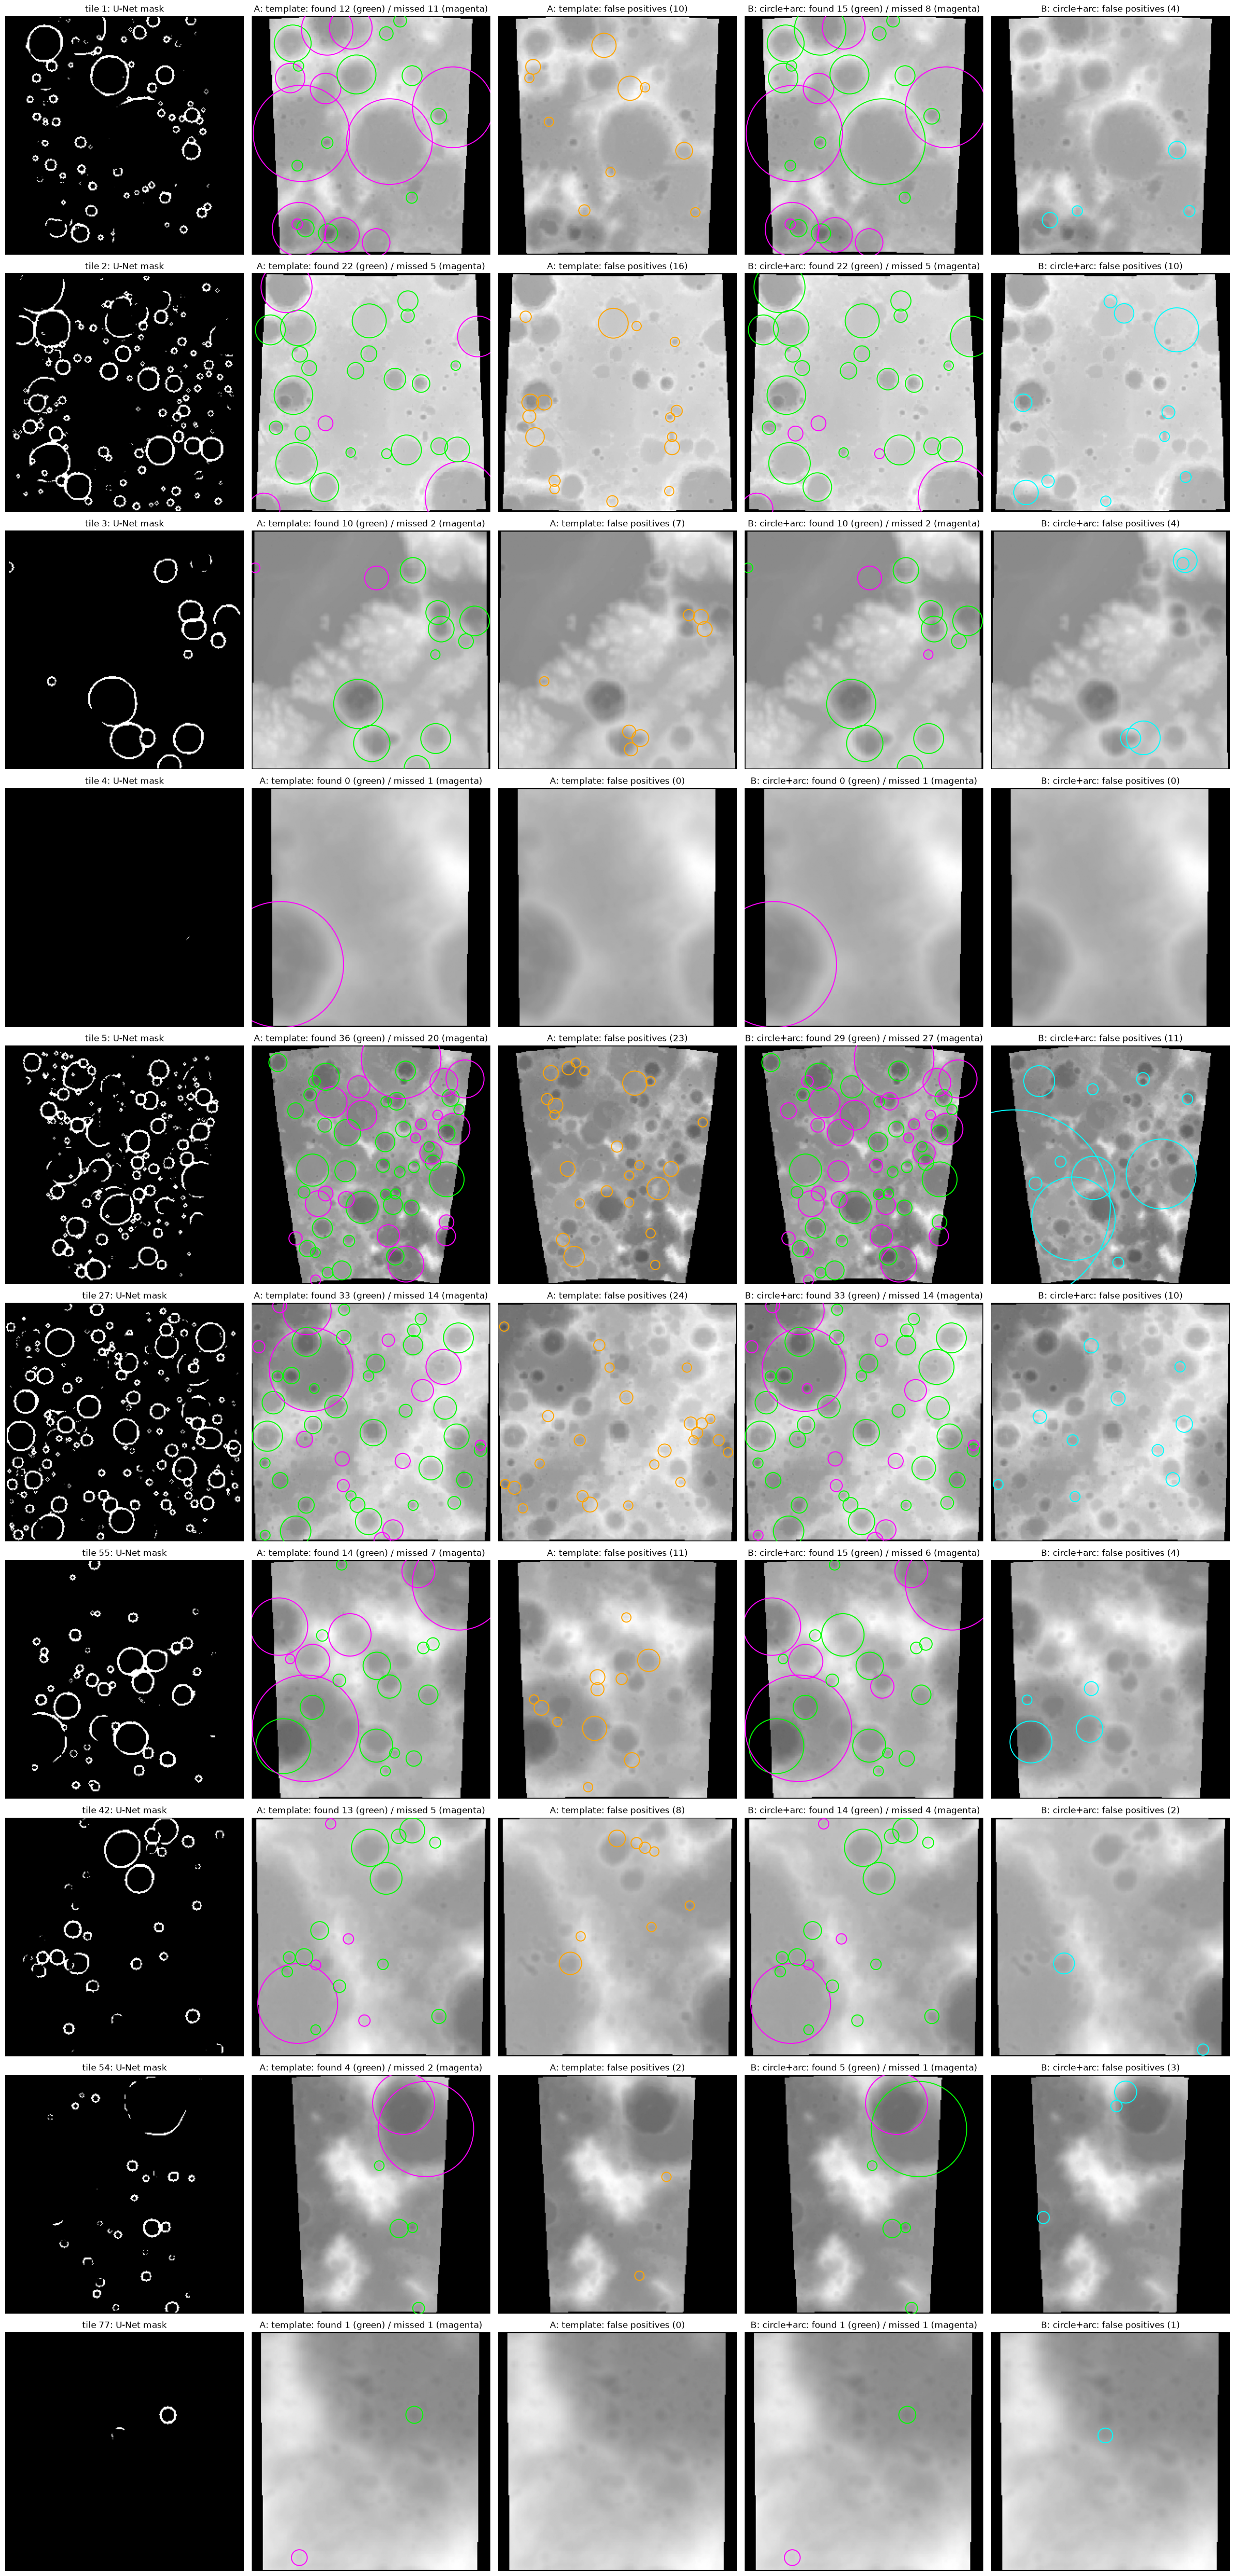

In [21]:
# failure analysis comparing both methods on the same tiles: found vs missed, and false positives
def failure_panel_compare_AB(tiles, min_r=5, D_xy=1.8, D_r=1.0):
    methods = [('A: template', extract_template, 'orange'),
               ('B: circle+arc', extract_circlearc, 'cyan')]
    # 5 columns per tile: mask, then found/missed + false positives for each method
    fig, ax = plt.subplots(len(tiles), 5, figsize=(24, 5*len(tiles)))
    stored = pd.HDFStore(SRC_CRATERS, 'r')
    for row, j in enumerate(tiles):
        mask = preds[j]; dem = X[j, ..., 0]
        cat = stored[f"/img_{j:05d}"]
        truth = [(c['x'], c['y'], c['Diameter (pix)']/2)
                 for _, c in cat.iterrows() if c['Diameter (pix)']/2 >= min_r] # catalogue craters above min_r
        # col 0: raw U-Net mask (shared input to both methods)
        ax[row,0].imshow(mask, cmap='gray'); ax[row,0].set_title(f'tile {j}: U-Net mask')
        for mi, (name, extractor, col) in enumerate(methods): # loop over both methods
            dets = [d for d in extractor(j) if d[2] >= min_r]
            # match detections to truth (same rule as everywhere)
            matched_t, matched_d = set(), set()
            sorted_d = sorted(dets, key=lambda d: -d[3])
            for di, (x, y, r, *_ ) in enumerate(sorted_d):
                for k, (tx, ty, tr) in enumerate(truth):
                    if k in matched_t: continue
                    if ((x-tx)**2+(y-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                        matched_t.add(k); matched_d.add(di); break
            false_pos = [sorted_d[di] for di in range(len(sorted_d)) if di not in matched_d]  # detections with no match
            n_found  = len(matched_t) # TP: catalogue craters correctly detected
            n_missed = len(truth) - n_found # FN: catalogue craters not detected
            # found/missed panel: draw every true crater, green if matched, magenta if missed
            c_fm = 1 + mi*2 # column index for this method's found/missed panel
            ax[row,c_fm].imshow(dem, cmap='gray')
            ax[row,c_fm].set_title(f'{name}: found {n_found} (green) / missed {n_missed} (magenta)')
            for k, (tx, ty, tr) in enumerate(truth):
                cc = 'lime' if k in matched_t else 'magenta'
                ax[row,c_fm].add_patch(Circle((tx, ty), tr, fill=False, color=cc, lw=1.4))
            # false positives panel: draw the detections that matched no catalogue crater
            c_fp = 2 + mi*2 # column index for this method's false-positive panel
            ax[row,c_fp].imshow(dem, cmap='gray')
            ax[row,c_fp].set_title(f'{name}: false positives ({len(false_pos)})')
            for x, y, r, s in false_pos:
                ax[row,c_fp].add_patch(Circle((x, y), r, fill=False, color=col, lw=1.4))
        for a in ax[row]: a.axis('off')
    stored.close()
    plt.tight_layout(); plt.show()

failure_panel_compare_AB([1, 2, 3, 4, 5, 27, 55, 42, 54, 77])

# Part II: Final Evaluation: Classical Baseline vs. U-Net

The baseline and the U-Net method are compared on the test set, differing only in the input the extraction runs on: the baseline uses the Sobel-edge image of the raw DEM, the U-Net method uses the U-Net mask.

The extraction itself is not completely identical. We found out, that on the U-Net mask, both template matching and circle-and-arc fitting work well and are combined but on the raw DEM, circle-and-arc fitting contributes almost nothing: it needs the clean, normalised ring structure of a U-Net mask, whereas the Sobel-edge image is too fragmented for the circle fit. So therefore the baseline uses only pure template matching. Its template-matching parameters were tuned on the validation set and are applied unchanged to test.

## 1. Baseline and U-Net extraction

In [22]:
# removing 0 and NaN values
def get_valid_mask(tile):
    return ~np.isnan(tile) & (tile != 0)

# Gaussian filter
def masked_blur(tile, sigma=3, mode='mirror'):
    valid = get_valid_mask(tile)
    tile_filled = np.where(valid, tile, 0.0)
    weight = valid.astype(float)
    blurred_data   = ndimage.gaussian_filter(tile_filled, sigma=sigma, mode=mode)
    blurred_weight = ndimage.gaussian_filter(weight, sigma=sigma, mode=mode)
    with np.errstate(invalid='ignore', divide='ignore'):
        smoothed = blurred_data / blurred_weight
    smoothed = np.where(blurred_weight > 1e-6, smoothed, 0.0)
    return smoothed, valid

# sobel edge detection
def sobel_edges(tile, sigma=3, erode_border=3, mode='mirror'):
    smoothed, valid = masked_blur(tile, sigma=sigma, mode=mode)
    valid_eroded = ndimage.binary_erosion(valid, iterations=erode_border)
    sx = ndimage.sobel(smoothed, axis=0, mode=mode)
    sy = ndimage.sobel(smoothed, axis=1, mode=mode)
    magnitude = np.sqrt(sx**2 + sy**2)
    p98 = np.percentile(magnitude[valid_eroded], 98) + 1e-8
    edge = np.clip(magnitude / p98, 0, 1)
    edge = np.where(valid_eroded, edge, 0.0)
    return edge, valid_eroded

# baseline detector (template matching on Sobel edges)
def detect_craters_tm(image, radii=range(1, 100, 1), threshold=0.35, min_distance=8, min_edge=0.01,
                       sigma=3, erode_border=3):
    edge, valid_eroded = sobel_edges(image, sigma=sigma, erode_border=erode_border)
    dets = []
    for r in radii:
        if 2*r + 1 >= min(edge.shape): # skip templates bigger than the tile
            continue
        corr = match_template(edge, make_ring(r), pad_input=True)
        peaks = peak_local_max(corr, threshold_abs=threshold, min_distance=min_distance)
        for y, x in peaks:
            ring = make_ring(r)
            y0, y1 = y - r, y + r + 1 # box around the candidate center
            x0, x1 = x - r, x + r + 1
            if y0 < 0 or x0 < 0 or y1 > edge.shape[0] or x1 > edge.shape[1]:
                continue

            if not valid_eroded[y0:y1, x0:x1].all():
                continue
            edge_on_ring = (edge[y0:y1, x0:x1] * ring).sum() / ring.sum() # mean edge value along the ring
            if edge_on_ring < min_edge: # too little actual edge: delete
                continue
            dets.append((x, y, r, corr[y, x]))
    return dets
# removing duplicates
def nms(dets, frac=0.6):
    kept = []
    for x, y, r, s in sorted(dets, key=lambda d: -d[3]):
        if all(np.hypot(x - kx, y - ky) > frac * max(r, kr) for kx, ky, kr, _ in kept):
            kept.append((x, y, r, s))
    return kept

def extract_baseline(j):
    return nms(detect_craters_tm(X[j, ..., 0]))

# above U-Net based methods
def extract_circlearc_on(image, tile_idx):
    dets, _ = detect_all_craters(image, tile_idx=tile_idx)
    return [(d['x'], d['y'], d['r'], d.get('coverage', 1.0)) for d in dets]

def extract_unet(j, D_xy=1.8, D_r=1.0):
    tm = detect_craters_deepmoon(preds[j], Pm=0.38)
    ca = extract_circlearc_on(preds[j], j)
    kept = []
    for x, y, r, s in tm + ca:
        if not any(((x-kx)**2+(y-ky)**2)/min(r,kr)**2 < D_xy and abs(r-kr)/min(r,kr) < D_r
                   for kx, ky, kr, _ in kept):
            kept.append((x, y, r, s))
    return kept

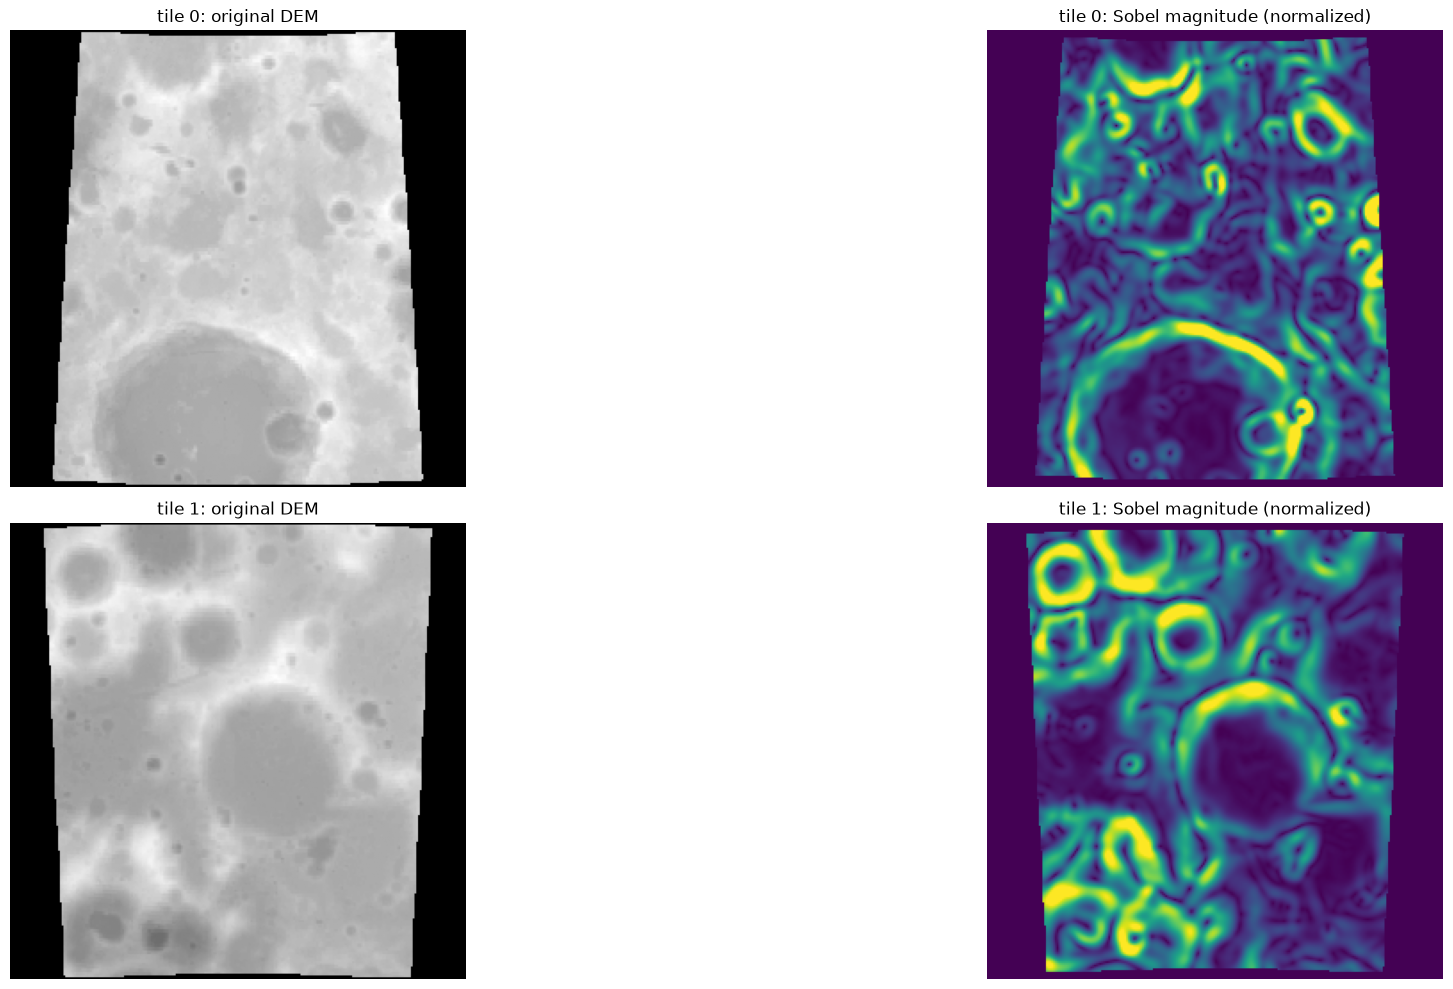

In [23]:
n_tiles = 2
fig, ax = plt.subplots(n_tiles, 2, figsize=(25, 5*n_tiles))
for row, j in enumerate(range(n_tiles)):
    dem = X[j, ..., 0]
    smoothed, valid = masked_blur(dem, sigma=3)
    edge, valid_eroded = sobel_edges(dem, sigma=3, erode_border=3)
    ax[row, 0].imshow(dem, cmap='gray')
    ax[row, 0].set_title(f'tile {j}: original DEM')
    ax[row, 1].imshow(edge, cmap='viridis')
    ax[row, 1].set_title(f'tile {j}: Sobel magnitude (normalized)')
    for a in ax[row]:
        a.axis('off')

plt.tight_layout()
plt.savefig("sobel_edge_detection.png", dpi=200, bbox_inches='tight')
plt.show()

## 2. Detection accuracy in pixels

Same pixel-radius bands as Part I, now applied to the baseline and the combined U-Net method, as a quick consistency check before the kilometre-based dating-bias analysis in section 4.

In [31]:
N_EVAL = 4000

for r_min, r_max in [(1, 100), (1, 50), (5, 50)]:
    pb, rb, fb = evaluate_px_band(N_EVAL, extract_baseline, r_min, r_max)
    pu, ru, fu = evaluate_px_band(N_EVAL, extract_unet, r_min, r_max)
    print(f"\n=== pixel radius {r_min}-{r_max} px ===")
    print(f"{'method':<22} {'precision':>10} {'recall':>10} {'F1':>10}")
    print(f"{'Baseline: Sobel+TM':<22} {pb:>10.3f} {rb:>10.3f} {fb:>10.3f}")
    print(f"{'U-Net: TM+circle/arc':<22} {pu:>10.3f} {ru:>10.3f} {fu:>10.3f}")



=== pixel radius 1-100 px ===
method                  precision     recall         F1
Baseline: Sobel+TM          0.101      0.227      0.140
U-Net: TM+circle/arc        0.772      0.445      0.565

=== pixel radius 1-50 px ===
method                  precision     recall         F1
Baseline: Sobel+TM          0.101      0.228      0.140
U-Net: TM+circle/arc        0.773      0.447      0.566

=== pixel radius 5-50 px ===
method                  precision     recall         F1
Baseline: Sobel+TM          0.081      0.442      0.137
U-Net: TM+circle/arc        0.639      0.746      0.688


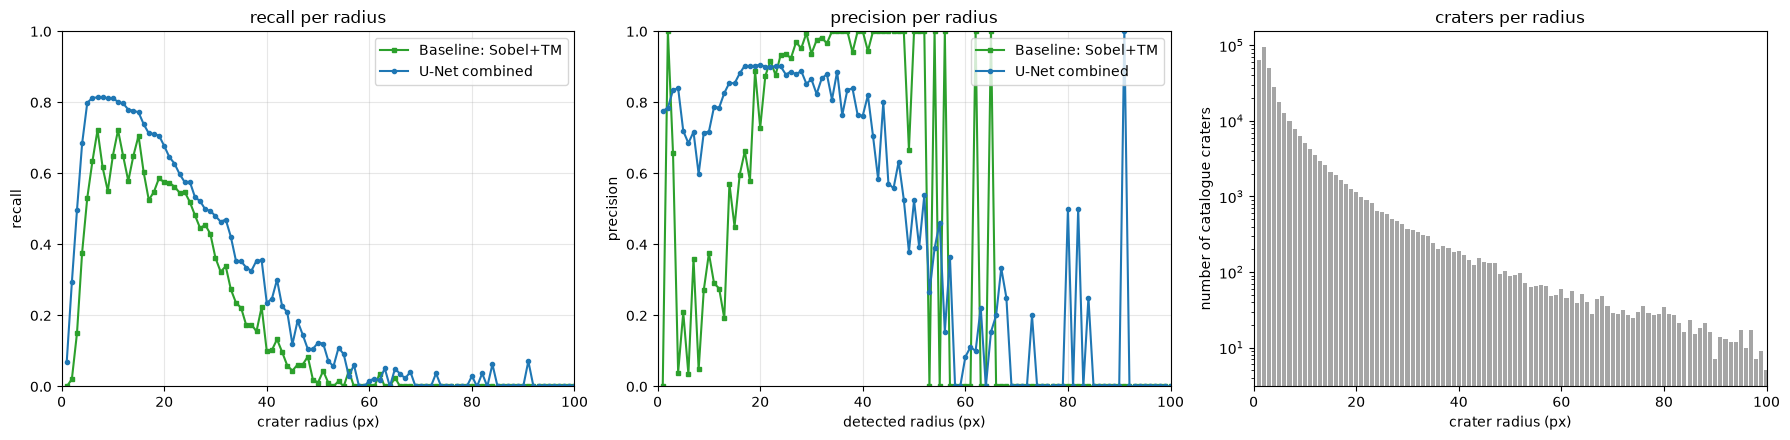

In [32]:
rb_x, rb_rec, rb_prec, rb_n = curves_per_radius(extract_baseline, N_EVAL)
ru_x, ru_rec, ru_prec, ru_n = curves_per_radius(extract_unet,      N_EVAL)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
# recall
ax[0].plot(rb_x, rb_rec, 's-', label='Baseline: Sobel+TM', color='tab:green', ms=3)
ax[0].plot(ru_x, ru_rec, 'o-', label='U-Net combined',     color='tab:blue',  ms=3)
ax[0].set_xlabel('crater radius (px)'); ax[0].set_ylabel('recall'); ax[0].set_title('recall per radius')
ax[0].set_ylim(0, 1); ax[0].set_xlim(0, 100); ax[0].legend(); ax[0].grid(alpha=0.3)
# precision
ax[1].plot(rb_x, rb_prec, 's-', label='Baseline: Sobel+TM', color='tab:green', ms=3)
ax[1].plot(ru_x, ru_prec, 'o-', label='U-Net combined',     color='tab:blue',  ms=3)
ax[1].set_xlabel('detected radius (px)'); ax[1].set_ylabel('precision'); ax[1].set_title('precision per radius')
ax[1].set_ylim(0, 1); ax[1].set_xlim(0, 100); ax[1].legend(); ax[1].grid(alpha=0.3)
# crater counts
ax[2].bar(rb_x, rb_n, width=0.8, alpha=0.7, color='tab:gray')
ax[2].set_xlabel('crater radius (px)'); ax[2].set_ylabel('number of catalogue craters')
ax[2].set_title('craters per radius'); ax[2].set_xlim(0, 100); ax[2].set_yscale('log')
plt.tight_layout(); plt.show()

## 3. Example tiles
Two visual checks on example tiles. 

The first shows how the two methods detect different craters: per tile the U-Net mask, then for each method the correctly found (green) vs. missed (magenta) craters and the false positives. 

The second shows that the catalogue itself misses some craters that the U-Net detects, comparing the human catalogue (red) against the U-Net detections (cyan) on the raw DEM. So some U-Net "false positives" are in fact real craters absent from the catalogue.

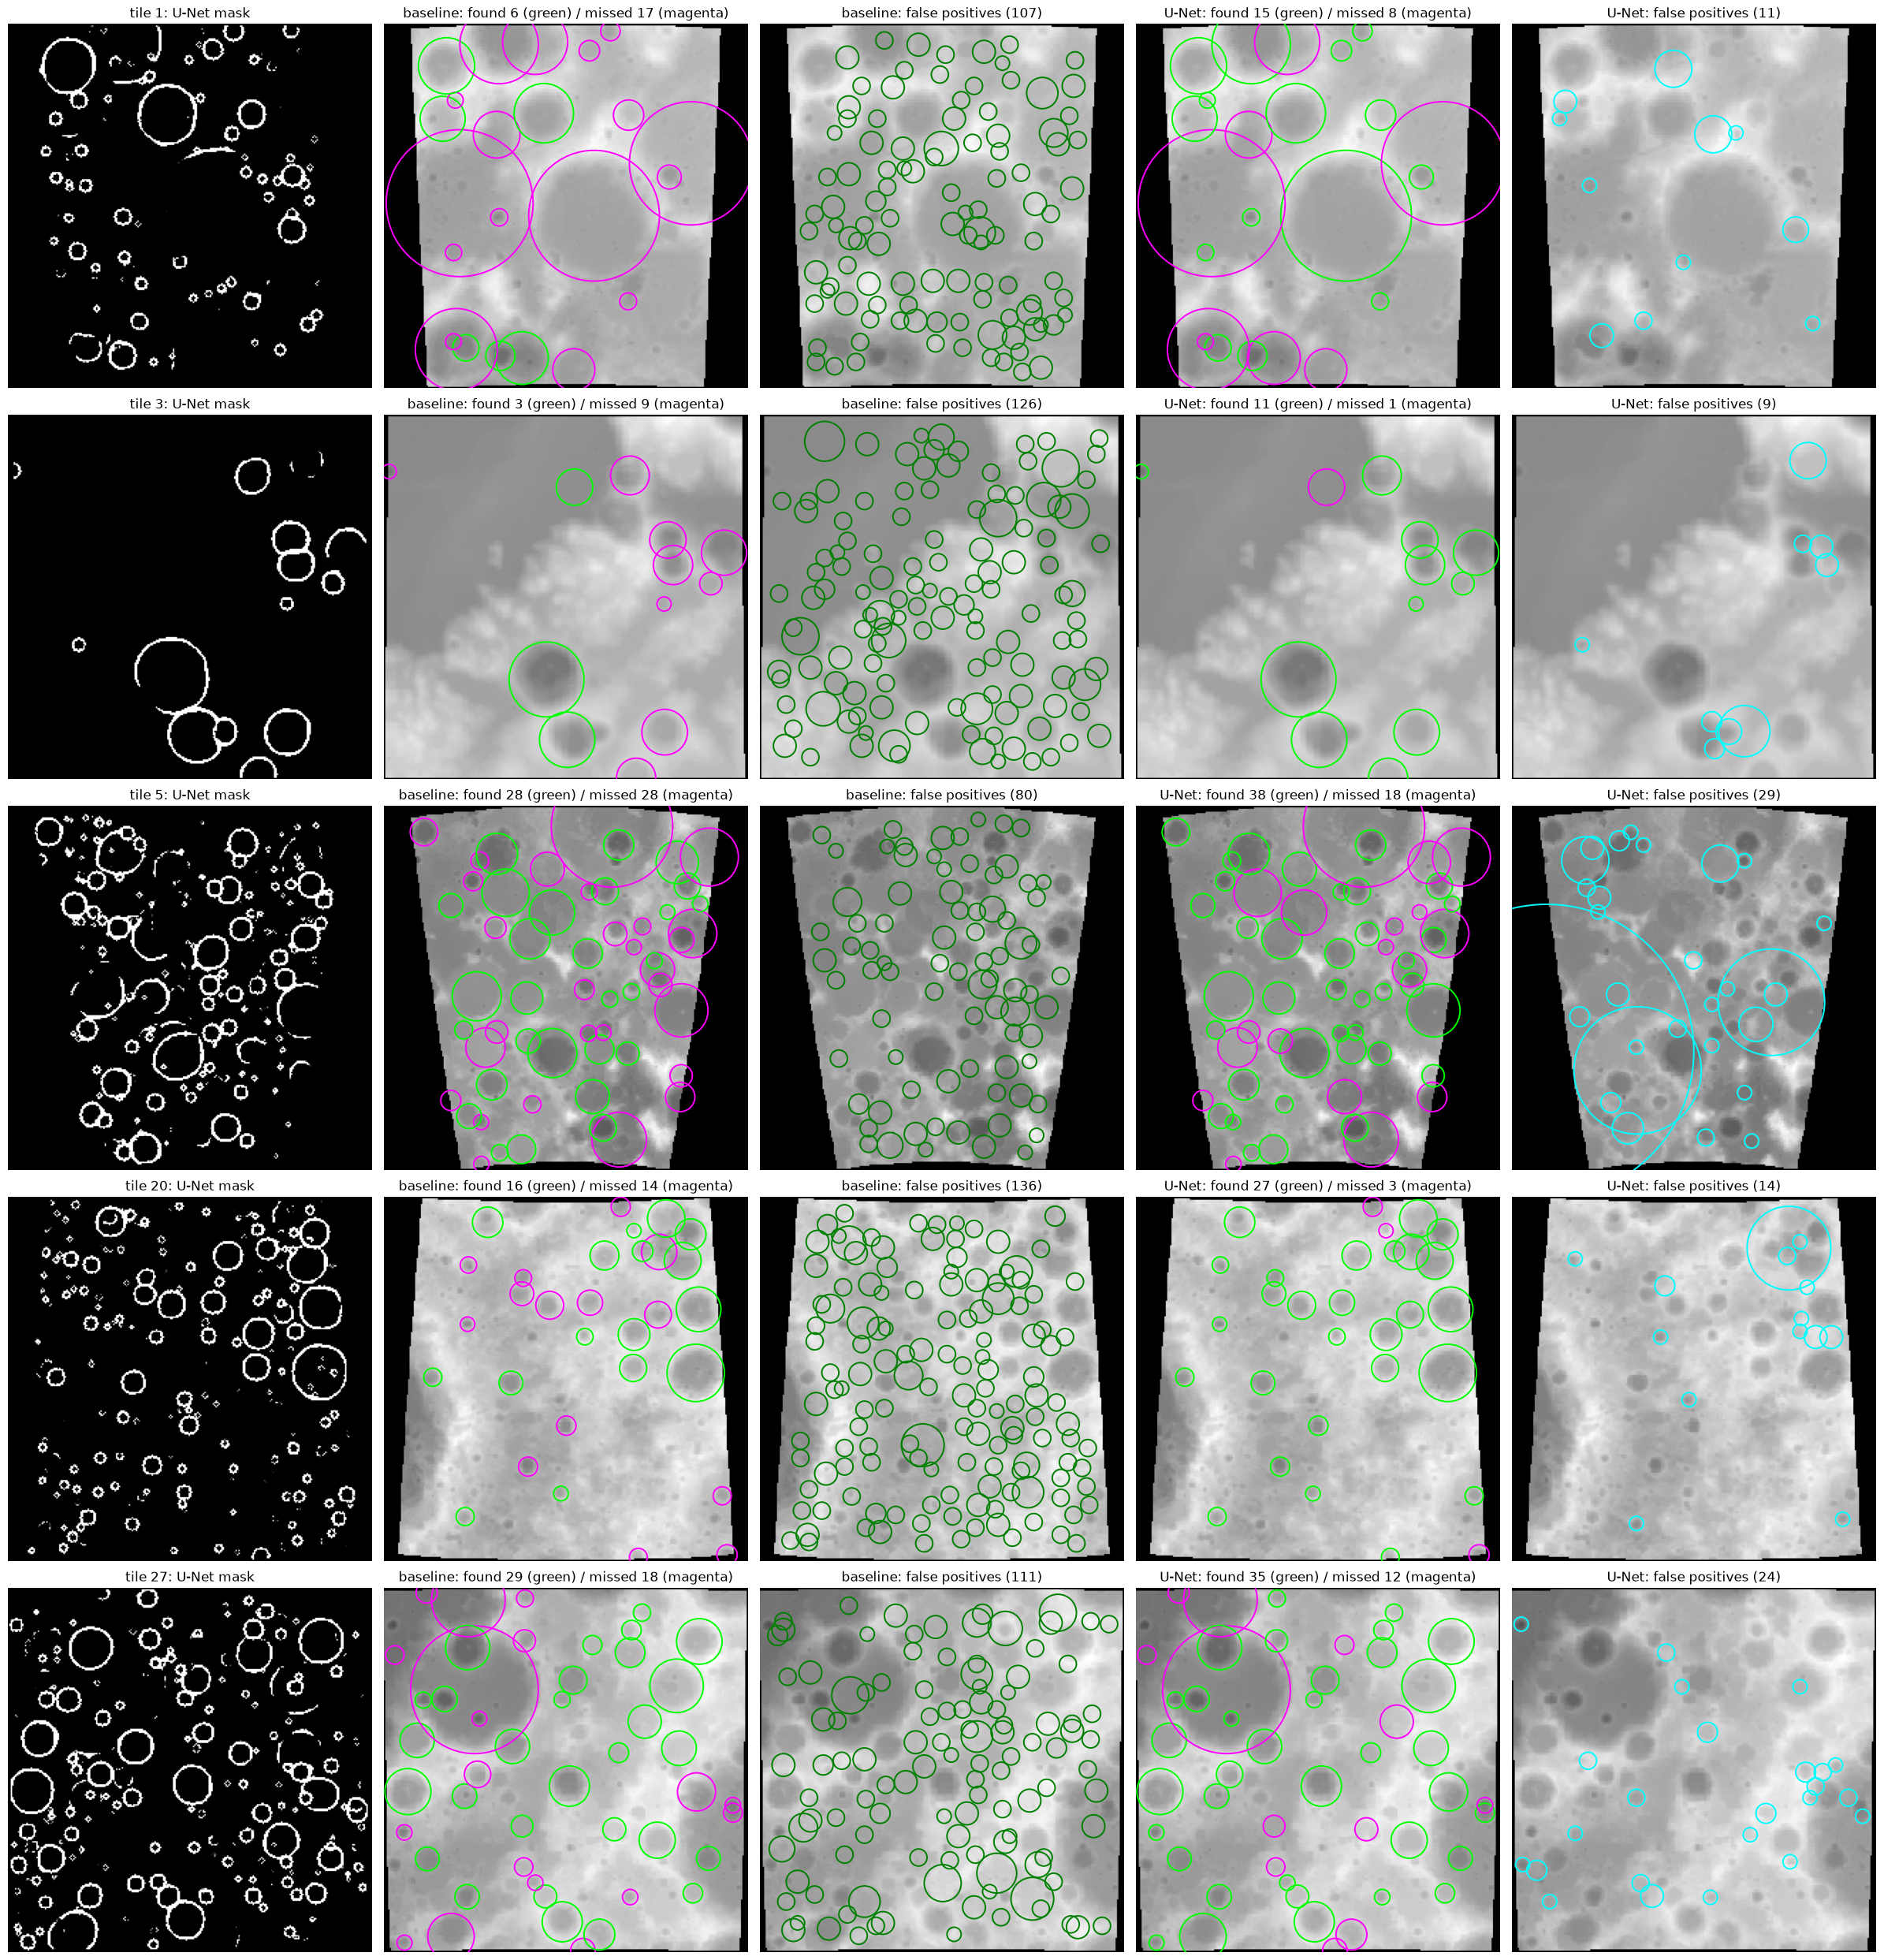

In [33]:
# baseline vs. U-net
# purpose: show how the different methods detect different craters (like above)
def failure_panel_compare_baseline_unet(tiles, min_r=5, D_xy=1.8, D_r=1.0):
    methods = [('baseline', extract_baseline, 'green'),
               ('U-Net',    extract_unet,     'cyan')]
    fig, ax = plt.subplots(len(tiles), 5, figsize=(24, 5*len(tiles)))
    stored = pd.HDFStore(SRC_CRATERS, 'r')
    for row, j in enumerate(tiles):
        mask = preds[j]; dem = X[j, ..., 0]
        cat = stored[f"/img_{j:05d}"]
        truth = [(c['x'], c['y'], c['Diameter (pix)']/2)
                 for _, c in cat.iterrows() if c['Diameter (pix)']/2 >= min_r]
        ax[row,0].imshow(mask, cmap='gray'); ax[row,0].set_title(f'tile {j}: U-Net mask')
        for mi, (name, extractor, col) in enumerate(methods):
            dets = [d for d in extractor(j) if d[2] >= min_r]
            matched_t, matched_d = set(), set()
            sorted_d = sorted(dets, key=lambda d: -d[3])
            for di, (x, y, r, *_ ) in enumerate(sorted_d):
                for k, (tx, ty, tr) in enumerate(truth):
                    if k in matched_t: continue
                    if ((x-tx)**2+(y-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                        matched_t.add(k); matched_d.add(di); break
            false_pos = [sorted_d[di] for di in range(len(sorted_d)) if di not in matched_d]
            n_found  = len(matched_t); n_missed = len(truth) - n_found
            c_fm = 1 + mi*2
            ax[row,c_fm].imshow(dem, cmap='gray')
            ax[row,c_fm].set_title(f'{name}: found {n_found} (green) / missed {n_missed} (magenta)')
            for k, (tx, ty, tr) in enumerate(truth):
                cc = 'lime' if k in matched_t else 'magenta'
                ax[row,c_fm].add_patch(Circle((tx, ty), tr, fill=False, color=cc, lw=1.4))
            c_fp = 2 + mi*2
            ax[row,c_fp].imshow(dem, cmap='gray')
            ax[row,c_fp].set_title(f'{name}: false positives ({len(false_pos)})')
            for x, y, r, s in false_pos:
                ax[row,c_fp].add_patch(Circle((x, y), r, fill=False, color=col, lw=1.4))
        for a in ax[row]: a.axis('off')
    stored.close()
    plt.tight_layout(); plt.show()

failure_panel_compare_baseline_unet([1, 3, 5, 20, 27])

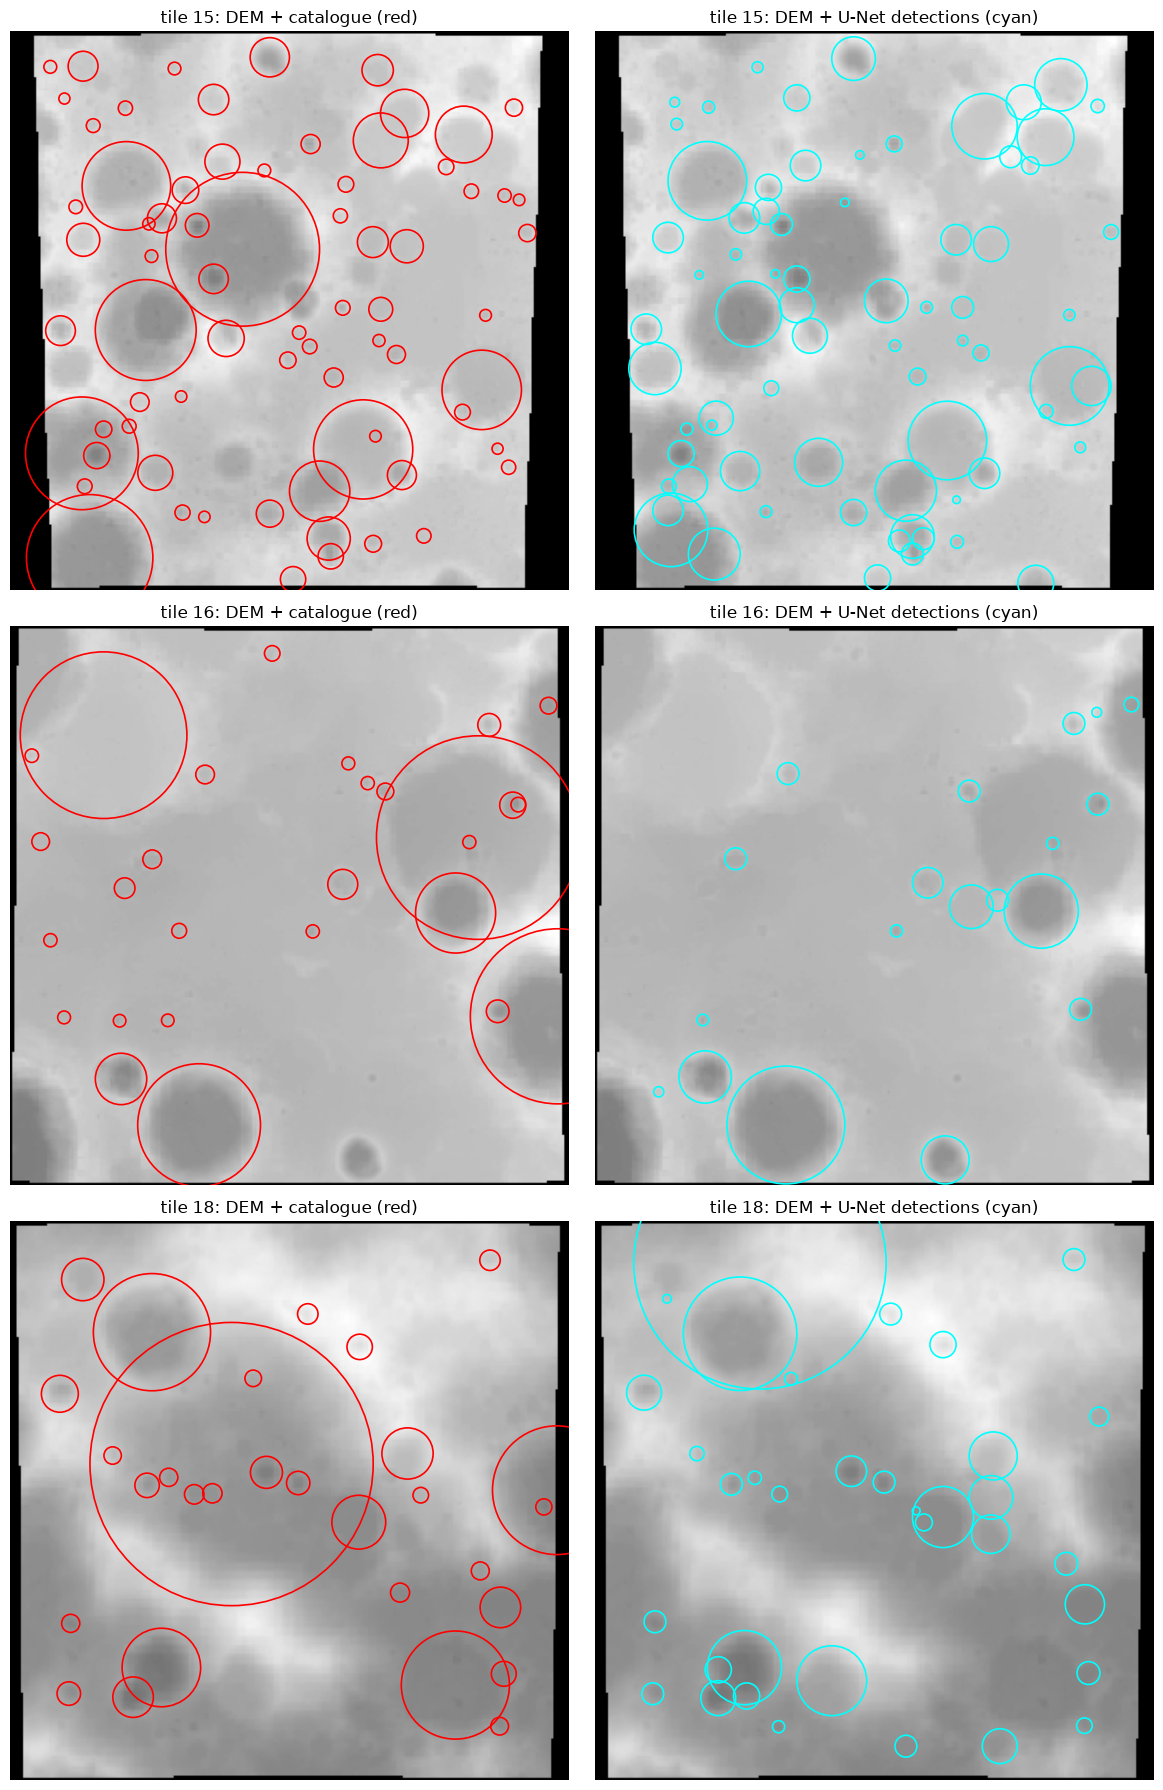

In [34]:
# raw DEM with catalogue (red) vs. raw DEM with U-Net detections (cyan)
# purpose: show that catalogue misses some craters which the U-Net detects
def catalogue_vs_unet(tiles):
    fig, ax = plt.subplots(len(tiles), 2, figsize=(12, 6*len(tiles)))
    stored = pd.HDFStore(SRC_CRATERS, 'r')
    for row, j in enumerate(tiles):
        dem = X[j, ..., 0]
        cat = stored[f"/img_{j:05d}"]
        dets = extract_unet(j)
        # left: DEM + catalogue (the human ground truth)
        ax[row,0].imshow(dem, cmap='gray'); ax[row,0].set_title(f'tile {j}: DEM + catalogue (red)')
        for _, c in cat.iterrows():
            ax[row,0].add_patch(Circle((c['x'], c['y']), c['Diameter (pix)']/2, fill=False, color='red', lw=1.2))
        # right: DEM + U-Net detections (some real craters here are missing from the catalogue)
        ax[row,1].imshow(dem, cmap='gray'); ax[row,1].set_title(f'tile {j}: DEM + U-Net detections (cyan)')
        for x, y, r, s in dets:
            ax[row,1].add_patch(Circle((x, y), r, fill=False, color='cyan', lw=1.2))
        for a in ax[row]: a.axis('off')
    stored.close()
    plt.tight_layout(); plt.savefig("Missing_craters_in_catalogue.png", dpi = 200,bbox_inches='tight' );plt.show()

catalogue_vs_unet([15, 16, 18])

## 4. Crater dating bias: size-frequency distribution and completeness
Surface age comes from crater density as a function of size (the SFD). A size-dependent detection bias distorts the SFD and the fitted age. Per 5-km bin (5 to 200 km) we show two quantities per method: completeness (correct detections / true, how many real craters are recovered) and raw detection ratio (all detections / true, what you would count on new data with no catalogue). Perfect is 1.0. 

We do not compute an actual surface age here, because a real age determination would require the exact surveyed area in square kilometres and the full non-linear chronology model, which is far too complex for this project. Instead we only look at the detection bias on the SFD itself, which is where a dating error would originate.

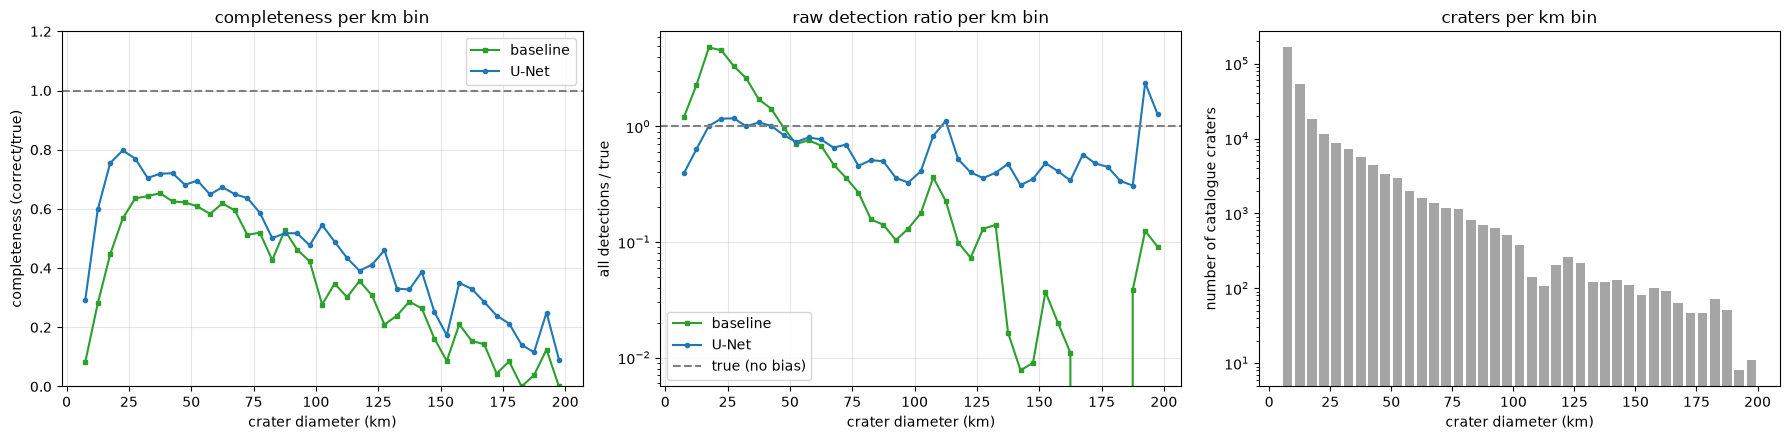

In [35]:
# per km bin: completeness (correct/true) and raw detection ratio (all detections/true)
def dating_curves(extractor, n_tiles, bins, D_xy=1.8, D_r=1.0):
    centers = (bins[:-1] + bins[1:]) / 2
    tp = np.zeros(len(centers)) # correctly detected true craters per bin
    nt = np.zeros(len(centers)) # true craters per bin (the truth)
    nd = np.zeros(len(centers)) # all detections per bin (incl. false positives)
    stored = pd.HDFStore(SRC_CRATERS, 'r')
    for j in range(n_tiles):
        cat = stored[f"/img_{j:05d}"]
        truth = [(c['x'], c['y'], c['Diameter (pix)']/2, diam_px_to_km(c['Diameter (pix)']/2, j))
                 for _, c in cat.iterrows()]
        truth = [t for t in truth if bins[0] <= t[3] <= bins[-1]]
        dets = [(d[0],d[1],d[2],d[3], diam_px_to_km(d[2], j)) for d in extractor(j)]
        dets = [d for d in dets if bins[0] <= d[4] <= bins[-1]]
        # match detections to truth
        matched_t = set()
        for x,y,r,s,km in sorted(dets, key=lambda d: -d[3]):
            for k, (tx,ty,tr,tkm) in enumerate(truth):
                if k in matched_t: continue
                if ((x-tx)**2+(y-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                    matched_t.add(k); break
        # bin true craters by their km-diameter: count all (nt) and the found ones (tp)
        for k, (tx,ty,tr,tkm) in enumerate(truth):
            b = np.searchsorted(bins, tkm) - 1
            if 0 <= b < len(centers):
                nt[b] += 1
                if k in matched_t: tp[b] += 1
        # bin all detections by km-diameter
        for x,y,r,s,km in dets:
            b = np.searchsorted(bins, km) - 1
            if 0 <= b < len(centers):
                nd[b] += 1
    stored.close()
    return centers, tp/(nt+1e-9), nd/(nt+1e-9), nt

bins_km = np.arange(5, 205, 5)
db_x, db_comp, db_raw, db_nt = dating_curves(extract_baseline, N_EVAL, bins_km)
du_x, du_comp, du_raw, du_nt = dating_curves(extract_unet,     N_EVAL, bins_km)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
# completeness
ax[0].plot(db_x, db_comp, 's-', label='baseline', color='tab:green', ms=3)
ax[0].plot(du_x, du_comp, 'o-', label='U-Net',    color='tab:blue',  ms=3)
ax[0].axhline(1.0, color='gray', ls='--')
ax[0].set_xlabel('crater diameter (km)'); ax[0].set_ylabel('completeness (correct/true)')
ax[0].set_title('completeness per km bin'); ax[0].set_ylim(0, 1.2); ax[0].legend(); ax[0].grid(alpha=0.3)
# raw detection ratio
ax[1].plot(db_x, db_raw, 's-', label='baseline', color='tab:green', ms=3)
ax[1].plot(du_x, du_raw, 'o-', label='U-Net',    color='tab:blue',  ms=3)
ax[1].axhline(1.0, color='gray', ls='--', label='true (no bias)')
ax[1].set_xlabel('crater diameter (km)'); ax[1].set_ylabel('all detections / true')
ax[1].set_title('raw detection ratio per km bin'); ax[1].set_yscale('log'); ax[1].legend(); ax[1].grid(alpha=0.3)
# crater counts
ax[2].bar(db_x, db_nt, width=4, alpha=0.7, color='tab:gray')
ax[2].set_xlabel('crater diameter (km)'); ax[2].set_ylabel('number of catalogue craters')
ax[2].set_title('craters per km bin'); ax[2].set_yscale('log')
plt.tight_layout(); plt.show()

In [36]:
# overall percentages over the full 5-200 km band
def overall_dating(extractor, n_tiles, d_min=5, d_max=200, D_xy=1.8, D_r=1.0):
    n_true = n_correct = n_detected = 0
    stored = pd.HDFStore(SRC_CRATERS, 'r')
    for j in range(n_tiles):
        cat = stored[f"/img_{j:05d}"]
        truth = [(c['x'], c['y'], c['Diameter (pix)']/2)
                 for _, c in cat.iterrows() if d_min <= diam_px_to_km(c['Diameter (pix)']/2, j) <= d_max]
        dets = [d for d in extractor(j) if d_min <= diam_px_to_km(d[2], j) <= d_max]
        matched = set()
        for x,y,r,*_ in sorted(dets, key=lambda d: -d[3]):
            for k,(tx,ty,tr) in enumerate(truth):
                if k in matched: continue
                if ((x-tx)**2+(y-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                    matched.add(k); break
        n_true += len(truth); n_correct += len(matched); n_detected += len(dets)
    stored.close()
    return n_true, n_correct, n_detected

print(f"{'method':<10} {'true':>7} {'correct':>8} {'all det.':>9} {'completeness':>13} {'raw ratio':>10}")
for name, ex in [('baseline', extract_baseline), ('U-Net', extract_unet)]:
    nt, nc, nd = overall_dating(ex, N_EVAL)
    print(f"{name:<10} {nt:>7} {nc:>8} {nd:>9} {nc/nt:>12.1%} {nd/nt:>10.2f}")
print("\ncompleteness = correct/true  |  raw ratio = all detections/true (>1 = would over-date, <1 = under-date)")

method        true  correct  all det.  completeness  raw ratio
baseline    291650    69546    532820        23.8%       1.83
U-Net       291650   133114    170645        45.6%       0.59

completeness = correct/true  |  raw ratio = all detections/true (>1 = would over-date, <1 = under-date)


## 5. Summary of key results

### Table 1: Method comparison (A/B/C), 2,000 tiles

| Pixel band | Method                | Precision | Recall | F1    |
|------------|------------------------|-----------|--------|-------|
| 1-100 px   | A: template matching  | 0.781     | 0.212  | 0.333 |
| 1-100 px   | B: circle+arc         | 0.823     | 0.347  | 0.488 |
| 1-100 px   | C: union (A+B)        | 0.764     | 0.370  | 0.499 |
| 1-50 px    | A: template matching  | 0.781     | 0.213  | 0.335 |
| 1-50 px    | B: circle+arc         | 0.824     | 0.348  | 0.490 |
| 1-50 px    | C: union (A+B)        | 0.765     | 0.372  | 0.500 |
| 5-50 px    | A: template matching  | 0.666     | 0.682  | 0.674 |
| 5-50 px    | B: circle+arc         | 0.795     | 0.653  | 0.717 |
| 5-50 px    | C: union (A+B)        | 0.637     | 0.745  | 0.687 |

### Table 2: Baseline vs. U-Net (combined), 4,000 tiles

| Pixel band | Method                 | Precision | Recall | F1    |
|------------|--------------------------|-----------|--------|-------|
| 1-100 px   | Baseline: Sobel+TM       | 0.099     | 0.214  | 0.135 |
| 1-100 px   | U-Net: TM+circle/arc     | 0.764     | 0.371  | 0.500 |
| 1-50 px    | Baseline: Sobel+TM       | 0.099     | 0.215  | 0.136 |
| 1-50 px    | U-Net: TM+circle/arc     | 0.765     | 0.373  | 0.501 |
| 5-50 px    | Baseline: Sobel+TM       | 0.082     | 0.404  | 0.136 |
| 5-50 px    | U-Net: TM+circle/arc     | 0.638     | 0.747  | 0.688 |

### Table 3: Crater dating summary, 4,000 tiles

| Method   | True   | Correct | All det. | Completeness | Raw ratio |
|----------|--------|---------|----------|---------------|-----------|
| baseline | 291650 | 65559   | 508004   | 22.5%         | 1.74      |
| U-Net    | 291650 | 114432  | 148343   | 39.2%         | 0.51      |

